In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lab6_utils import unpack_gridsearch, plot_grid_result

In [2]:
data = pd.read_csv('Data/Testing_Data.csv',index_col=0).dropna().reset_index(drop = True)

target_class = '%_mem_succs'
Thres = 0.5 

features = data.drop(columns=target_class).columns

Xtrain = data.iloc[:,:-1]
ytrain = data.iloc[:,-1]

Xtrain = Xtrain.drop(columns = 'valid_time')
ytrain = ytrain.between(Thres,1)

In [3]:
N = len(ytrain)
N1 = ytrain.sum()
N0 = N - N1
baseline_acc = max(N0, N1) / N

In [4]:
# Logistic Regression
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

logreg_pipe = Pipeline([
    ('scaler' , StandardScaler() ) ,
    ('model' , LogisticRegression(solver = 'liblinear') )
])
logreg_pipe.fit(Xtrain,ytrain)


l1_ratio = [0,1]
C = np.logspace(-5,1,10)

param_grid = {
    'model__l1_ratio': l1_ratio,
    'model__C': C
}

gs_logreg = GridSearchCV(logreg_pipe,param_grid = param_grid, scoring = 'accuracy',cv = 3, refit = 'accuracy')
gs_logreg.fit(Xtrain,ytrain)



,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': array([1.0000...00000000e+01]), 'model__l1_ratio': [0, 1]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0Controls the 

In [5]:
def hypersolve(model,param_grid):
    # 1. Create the pipeline model
    pipe = Pipeline([
    ('scaler' , StandardScaler() ) ,
    ('model' , model )
    ])

    # 2. Construct the `GridSearchCV` object as was done in part 5.2
    gs = GridSearchCV(pipe,param_grid = param_grid, scoring = 'accuracy',cv = 3, refit = 'accuracy')
    
    # 3. Run the grid search
    gs = gs.fit(Xtrain,ytrain)
    
    # 4. Run `unpack_gridsearch` to obtain the results dictionary.
    result = unpack_gridsearch(gs)

    # 5. Plot the result with `plot_grid_result`
    plot_grid_result(result)

    # 6. return result
    return result

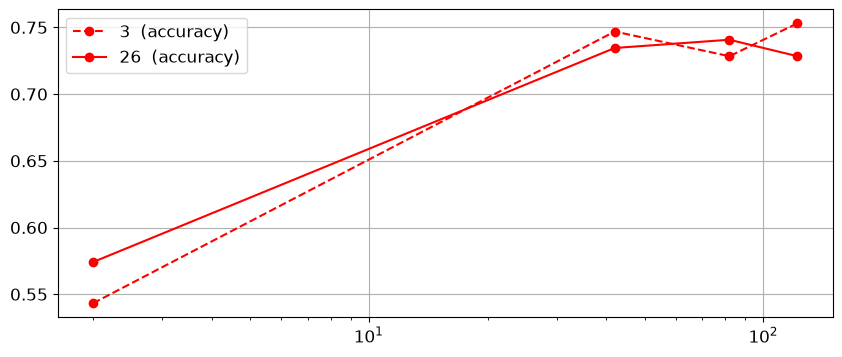

In [6]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

param_grid_rf = {
    'model__max_features': [3,Xtrain.shape[1]], # 4 was 3
    'model__n_estimators': [2,42,82,122]
}

model = RandomForestClassifier()

result_rf = hypersolve(model,param_grid_rf)


=== MDI Feature Importance (Descending) ===
totmembers           0.300665
tothired             0.263072
z300_min             0.028693
tcc_max              0.026727
daily_rainfall       0.025573
z300_max             0.024590
wind400_max          0.023464
temp400_max          0.023284
tcc_min              0.021667
z400_min             0.020820
z400_max             0.018515
temp400_mean         0.017505
wind400_mean         0.017174
wind400_min          0.016621
wind300_max          0.016584
temp300_max          0.016514
temp300_mean         0.016199
prev_day_rainfall    0.016083
wind300_min          0.015178
tcc_mean             0.014694
r300_mean            0.014482
temp400_min          0.014274
r400_mean            0.013847
wind300_mean         0.013722
temp300_min          0.013497
host                 0.006558
dtype: float64

=== Permutation Feature Importance (Descending) ===
tothired             0.124691
totmembers           0.104321
tcc_max              0.013580
wind300_max       

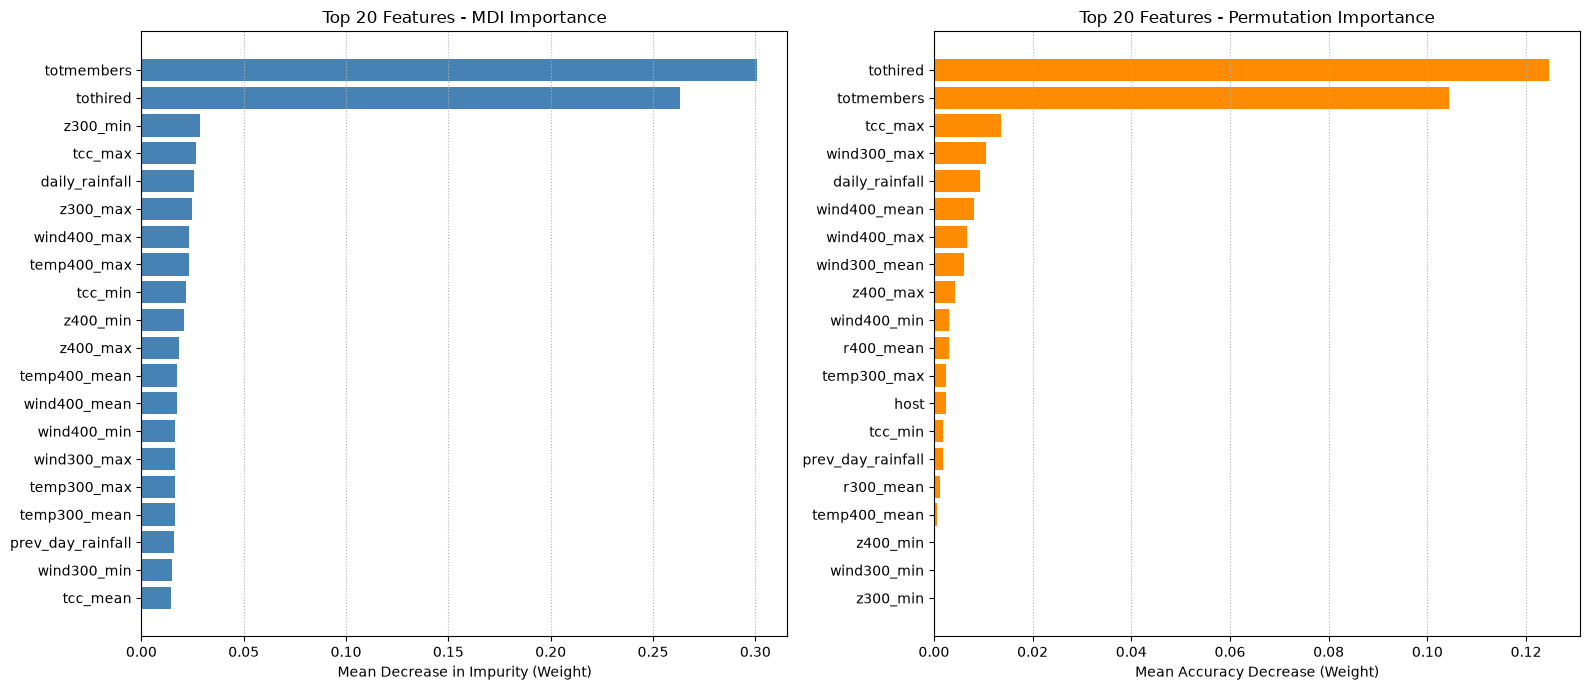

In [7]:
from sklearn.inspection import permutation_importance

# 1. Extract the best fitted pipeline and the underlying Random Forest estimator
best_rf_pipe = result_rf['best_estimator']
best_rf_model = best_rf_pipe.named_steps['model']
feature_names = Xtrain.columns

# 2. MDI (Mean Decrease in Impurity) Importance
mdi_importances = pd.Series(
    best_rf_model.feature_importances_, 
    index=feature_names
).sort_values(ascending=False)

# 3. Permutation Importance
perm_result = permutation_importance(
    best_rf_pipe, Xtrain, ytrain, 
    n_repeats=10, random_state=42, n_jobs=-1
)
perm_importances = pd.Series(
    perm_result.importances_mean, 
    index=feature_names
).sort_values(ascending=False)

# 4. Print both lists in descending order (most to least important)
print("=== MDI Feature Importance (Descending) ===")
print(mdi_importances)
print("\n=== Permutation Feature Importance (Descending) ===")
print(perm_importances)

# 5. Plot 2 bar graphs showing the top 20 most important features and their weights
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Top 20 MDI (plotted ascending on barh so #1 sits at the top)
top20_mdi = mdi_importances.head(20)[::-1]
axes[0].barh(top20_mdi.index, top20_mdi.values, color='steelblue')
axes[0].set_title('Top 20 Features - MDI Importance')
axes[0].set_xlabel('Mean Decrease in Impurity (Weight)')
axes[0].grid(axis='x', linestyle=':')

# Top 20 Permutation
top20_perm = perm_importances.head(20)[::-1]
axes[1].barh(top20_perm.index, top20_perm.values, color='darkorange')
axes[1].set_title('Top 20 Features - Permutation Importance')
axes[1].set_xlabel('Mean Accuracy Decrease (Weight)')
axes[1].grid(axis='x', linestyle=':')

plt.tight_layout()
plt.show()

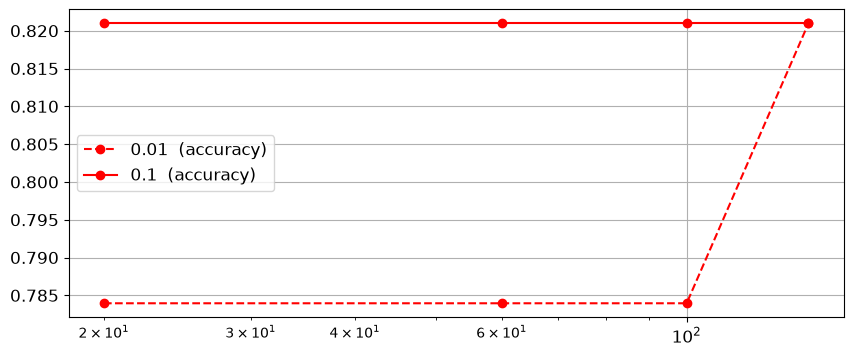

In [8]:
# AdaBoost
from sklearn.ensemble import AdaBoostClassifier

param_grid_ab = {
    'model__learning_rate': [0.01,0.1],
    'model__n_estimators': [20,60,100,140]
}

model = AdaBoostClassifier()

result_ab = hypersolve(model, param_grid_ab)

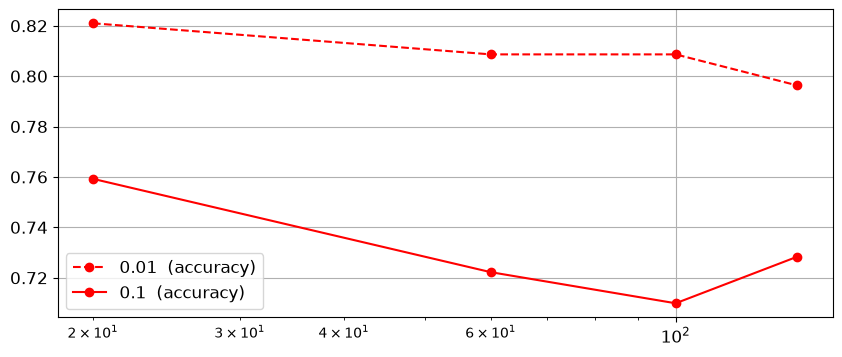

In [9]:
# Gradient Boosted Trees
from sklearn.ensemble import GradientBoostingClassifier

param_grid_gbt = {
    'model__learning_rate': [0.01,0.1],
    'model__n_estimators':[20,60,100,140]
}

model = GradientBoostingClassifier()

result_gbt = hypersolve(model, param_grid_gbt)

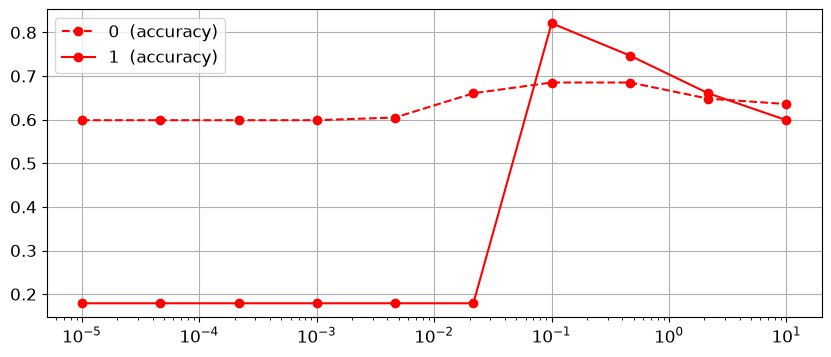

In [ ]:
from sklearn.metrics import accuracy_score

# re-solve logistic regression
param_grid_lr = {
    'model__l1_ratio' : [0,1],
    'model__C' : np.logspace(-5,1,10) }
result_lr = hypersolve( LogisticRegression(solver='liblinear'), param_grid_lr)

all_models = [
    ('logreg',result_lr['best_estimator'], result_lr['best_score']),
    ('rf',result_rf['best_estimator'], result_rf['best_score']),
    ('ab',result_ab['best_estimator'], result_ab['best_score']),
    ('gbt',result_gbt['best_estimator'], result_gbt['best_score']),
]

all_models_df = pd.DataFrame(all_models, columns = ['name','estimator','score'])

best_row = all_models_df.loc[all_models_df['score'].idxmax()]
best_name = best_row['name']
best_model = best_row['estimator']
best_score = best_row['score']


print(best_model)